# Gradient Boosting

- It is a boosting algorithm that builds an additive model in a forward stage-wise fashion.

- We will first see it for regression as it is easier to understand for this algorithm, and then for classification.

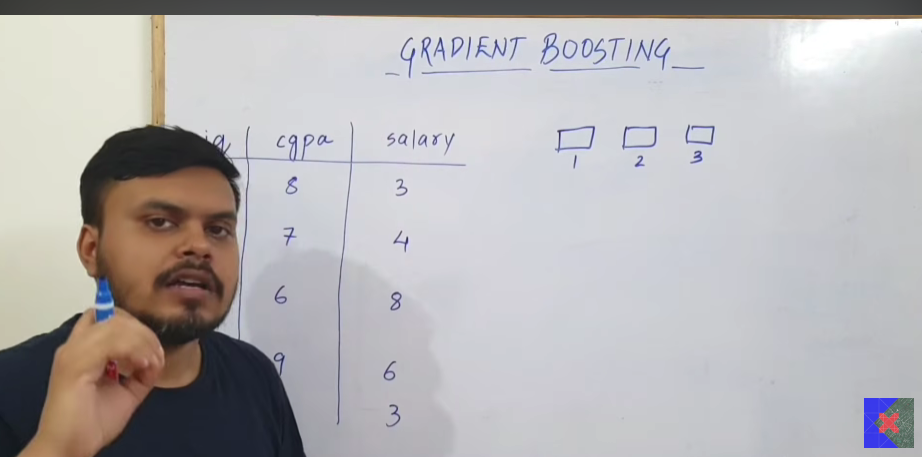

- So we will start with the above dataset, and will 3 base models for the ensemble

# Gradient Boosting for Regression

#### Step 1: Fit the first base model

- When applying gradient boosting for regression, our first base model will be the **mean of the target variable**.

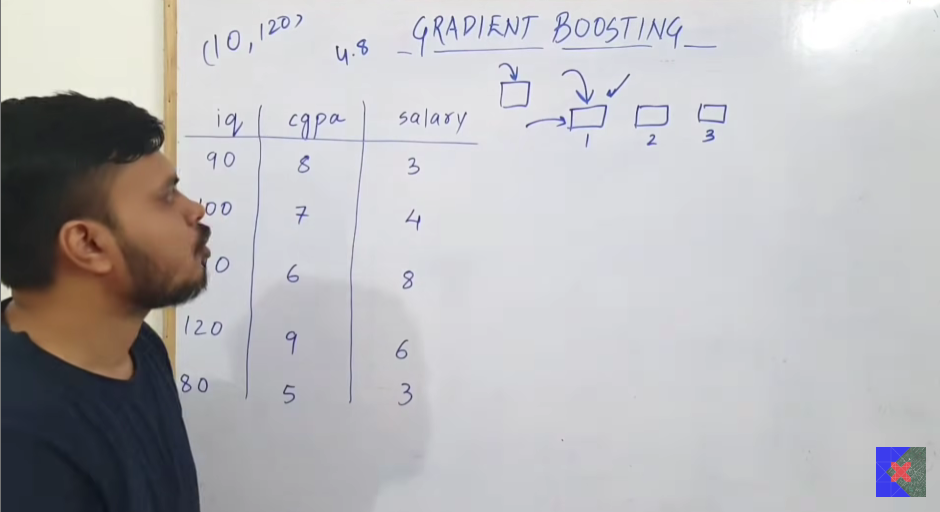

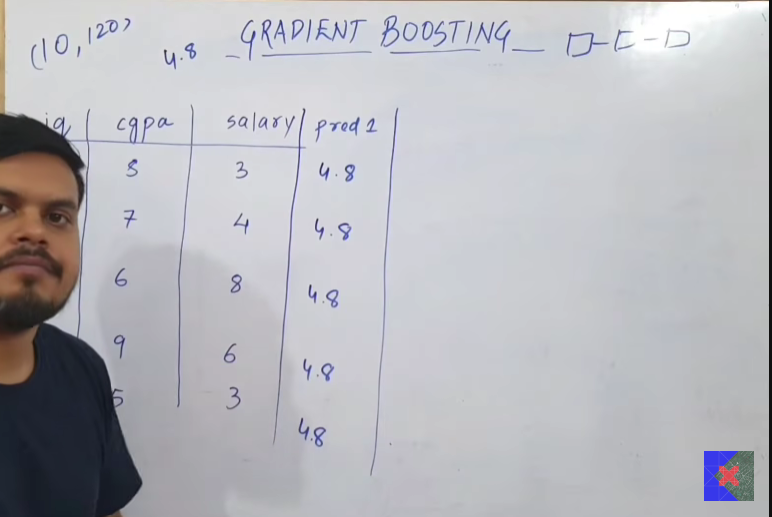

- So for every sample in the dataset, we will predict the mean of the target variable as the prediction of the first base model.

#### Step 2: Calculate the pseudo-residuals for the first base model 

- The pseudo-residuals are the difference between the actual target values and the predicted values from the first base model.

$$ r_i = y_i - \hat{y}_{i} $$

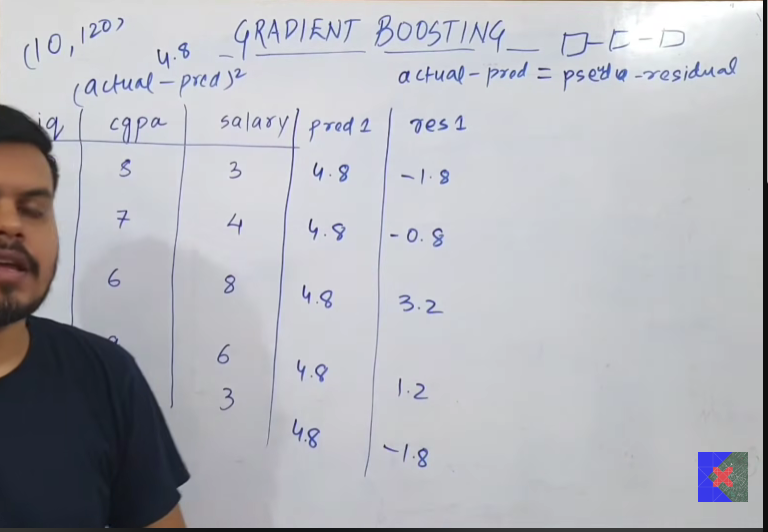

#### Step 3: Now some how we will have to tell the next base model the errors of the previous base model

- Our Model 2 will be **Desicion Tree**.
- You can use other base models as well, but Desicion Tree is the most commonly used base model for Gradient Boosting as it proven to work well in practice.

- For the second base model, $iq$ and $cgpa$ will be the input features and the **pseudo-residuals** from the first base model will be the target variable.

- So model 2 se hum salary kitni hai ye nhi predict karana chah rhe hai, hum model 2 se ye predict karana chah rhe hai ki model 1 ne kitni galti ki hai given the input features, yaani ki pseudo-residuals ko predict karana chah rhe hai.

- So jitna acurately model 2 pseudo-residuals ko predict karega, utna hi easily hum ek model bana payenge jo ki salary ko accurately predict karega.

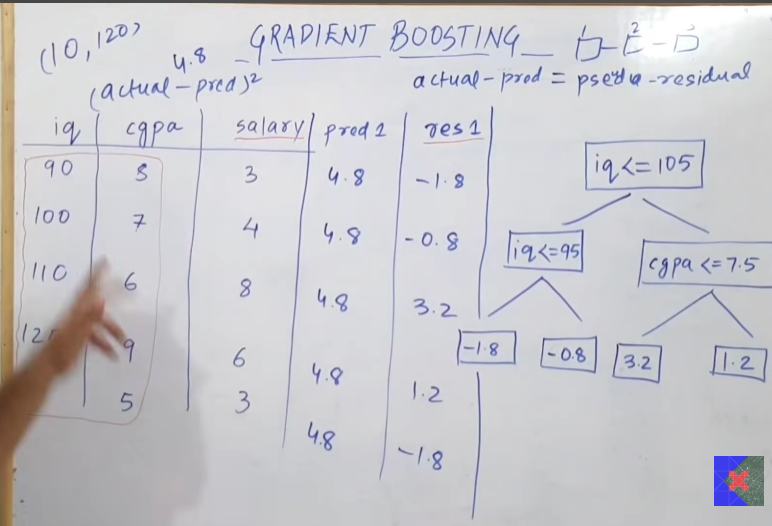

- Now after fitting the second base model, predict the pseudo-residuals using the second base model ($pred_2$)

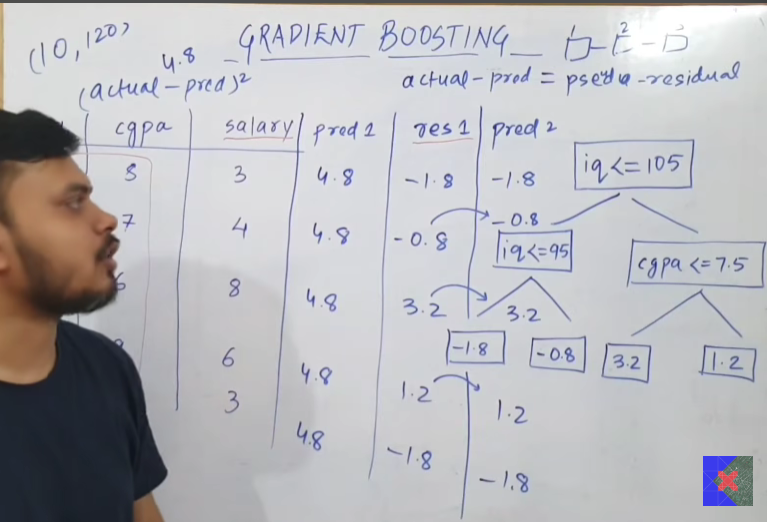

- You can see that the desicion tree is overfitting the pseudo-residuals, because the data was small (This desicion tree was made using code, and then drawn in the whiteboard)

- But anyways, by this point we have model 1 and model 2 ready

- So if our gradient boosting had just 2 base models, then the final prediction of the gradient boosting model would be:
    $$ Final Prediction = pred_1 + pred_2 $$

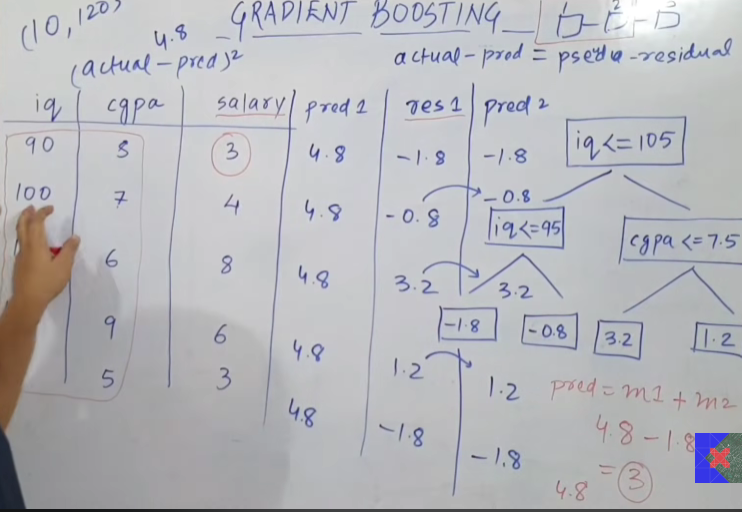

- But here as you can see **overfitting** is happening, so we will add a **learning rate** to the final prediction, which will help us to reduce the overfitting.

$$ Final Prediction = pred_1 + \eta * pred_2 $$

- So in Gradient Boosting, we multiply each subsequent base model's prediction with a learning rate ($\eta$) to reduce overfitting.

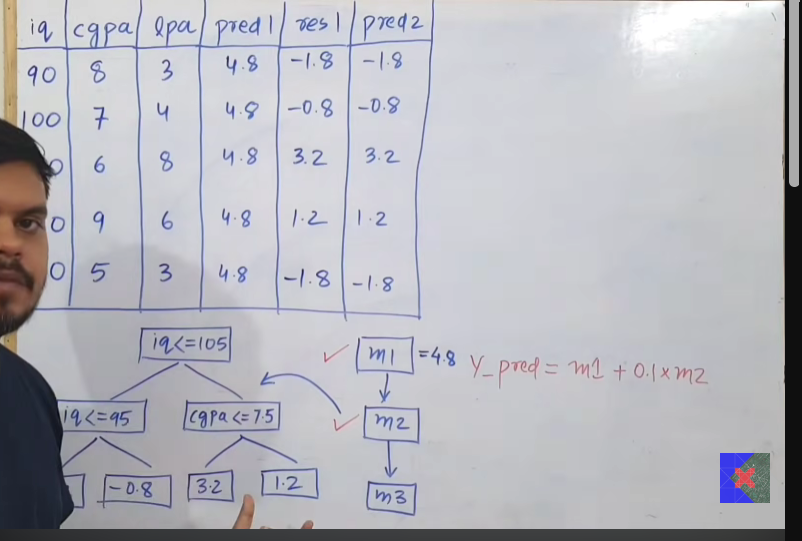

#### Step 4: Now we will calcualte the pseudo-residuals after fitting the second base model

$$ res_2 = y_{actual} - (final prediction using 2 base models) $$
$$ res_2 = y - (pred_1 + \eta * pred_2) $$

#### <span style="color:orange">NOTE: The pseudo-residuals are calculated using the final prediction of the gradient boosting model, which is the sum of the predictions of all the base models multiplied by the learning rate. And not using the predictions of individual base models.</span>

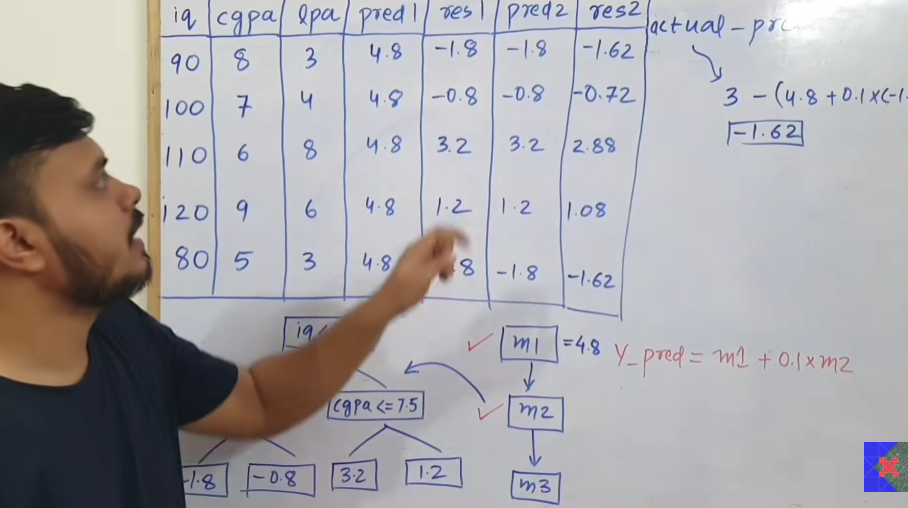

- As we add more and more base models, the residuals will keep decreasing, and the final prediction will keep getting better and better.



#### Stage 5: Fit the third base model

- Model 3 will also be a desicion tree, and the input features will be $iq$ and $cgpa$, and the target variable will be the pseudo-residuals from the previous stage ($res_2$).

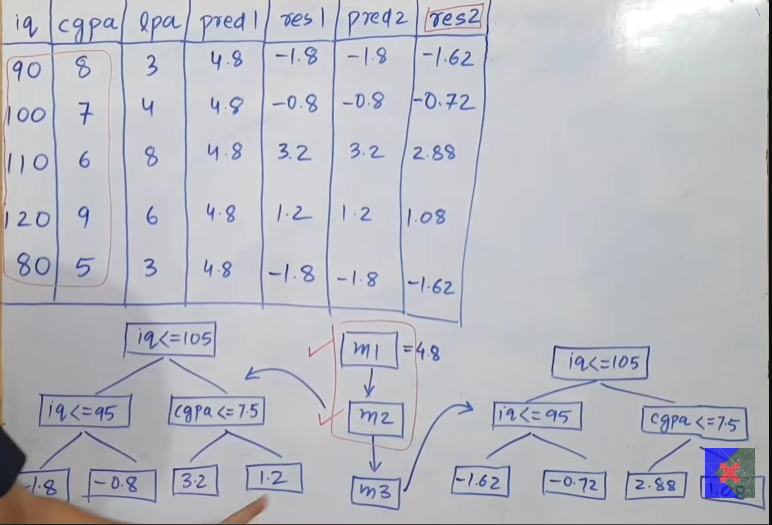

- We fitted the desicion tree, as you can see in the above image, it is overfitting the pseudo-residuals because the data was small, but anyways we have model 3 ready.

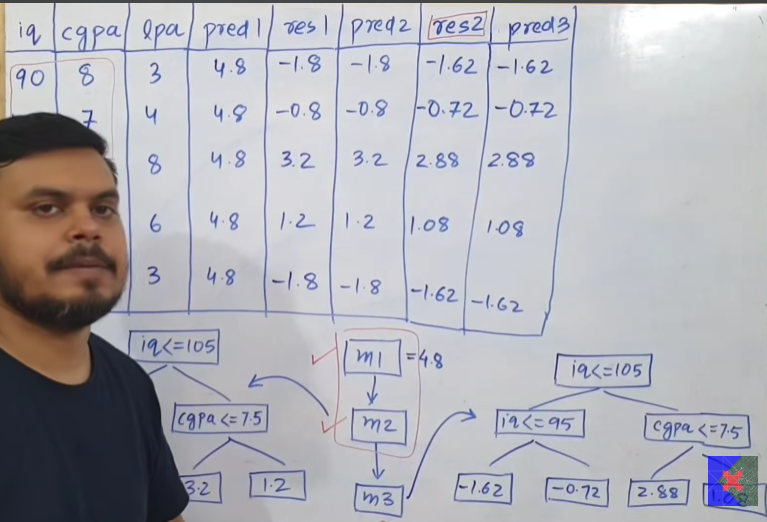

- $pred_3$ = prediction of the pseudo-residuals using model 3. Not the prediction of the target variable.

#### Stage 6: Predict the final prediction using 3 base models

### $$ Final Prediction = pred_1 + \eta * pred_2 + \eta * pred_3 $$

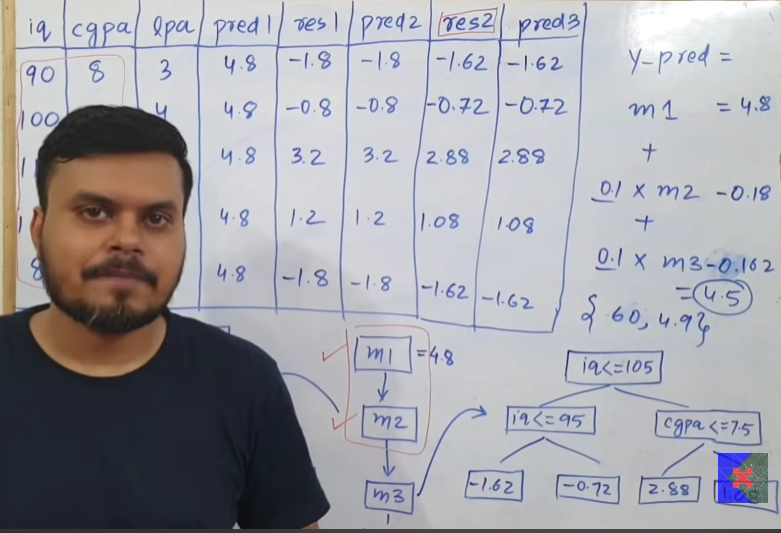

<hr>

- Now if there would have 4 base models then we would calculate the pseudo-residuals after fitting the third base model as follows:
    $$ res_3 = y - (pred_1 + \eta * pred_2 + \eta * pred_3) $$

- And then we would fit the fourth base model using the pseudo-residuals from the previous stage ($res_3$) as the target variable.

See the [code](./1.2-Gradient_boost_step_by_step.ipynb) for the implementation of the above steps and see how the predictions of the gradient boosting model improve as we add more and more base models.

# Note:

- In Gradient Boosting, We don't use desicion stumps as base models, we use desicion trees with `max_leaves= [8 to 32]` as base models. 

- It is proven by reasearchers that using desicion trees with `max_leaves= [8 to 32]` as base models gives better results than using desicion stumps as base models.